## **Importing Dependencies and Data**

In [38]:
import math
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import seaborn as sbn


In [2]:
# Import:
df = pd.read_csv("C:/Users/david/Downloads/student_lifestyle_dataset..csv", 
                 names=["student_id", "study_hours_per_day", "extracurricular_hours_per_day",
                        "sleep_hours_per_day", "social_hours_per_day", "physical_activity_hours_per_day",
                        "stress_level", "gender", "grades"])

# Drop ID:
df = df.drop(labels="student_id", axis=1)

## **Examining Data**

In [36]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   study_hours_per_day              2000 non-null   float64
 1   extracurricular_hours_per_day    2000 non-null   float64
 2   sleep_hours_per_day              2000 non-null   float64
 3   social_hours_per_day             2000 non-null   float64
 4   physical_activity_hours_per_day  2000 non-null   float64
 5   stress_level                     2000 non-null   str    
 6   gender                           2000 non-null   str    
 7   grades                           2000 non-null   float64
dtypes: float64(6), str(2)
memory usage: 125.1 KB


`gender` and `stress_level` as strings implies categorical values.  
No data types seem to be mismatched.

In [4]:
df.describe(include="all")

,study_hours_per_day,extracurricular_hours_per_day,sleep_hours_per_day,social_hours_per_day,physical_activity_hours_per_day,stress_level,gender,grades
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.00000,2000,2000,2000.000000
unique,NaN,NaN,NaN,NaN,NaN,3,2,NaN
top,NaN,NaN,NaN,NaN,NaN,High,Male,NaN
freq,NaN,NaN,NaN,NaN,NaN,1029,1016,NaN
mean,7.475800,1.990100,7.501250,2.704550,4.32830,NaN,NaN,7.789825
std,1.423888,1.155855,1.460949,1.688514,2.51411,NaN,NaN,0.746777
min,5.000000,0.000000,5.000000,0.000000,0.00000,NaN,NaN,5.600000
25%,6.300000,1.000000,6.200000,1.200000,2.40000,NaN,NaN,7.250000
50%,7.400000,2.000000,7.500000,2.600000,4.10000,NaN,NaN,7.780000
75%,8.700000,3.000000,8.800000,4.100000,6.10000,NaN,NaN,8.320000


`count` being equal in all columns indicates that there are no missing values.  
`unique = 2` in genders implies binary gendering.  
`unique = 3` in stress implies three category categorisation of stress levels.
`max` of `physical activity` being 13 hours indicates an outlier.

array([[<Axes: title={'center': 'study_hours_per_day'}>,
        <Axes: title={'center': 'extracurricular_hours_per_day'}>],
       [<Axes: title={'center': 'sleep_hours_per_day'}>,
        <Axes: title={'center': 'social_hours_per_day'}>],
       [<Axes: title={'center': 'physical_activity_hours_per_day'}>,
        <Axes: title={'center': 'grades'}>]], dtype=object)

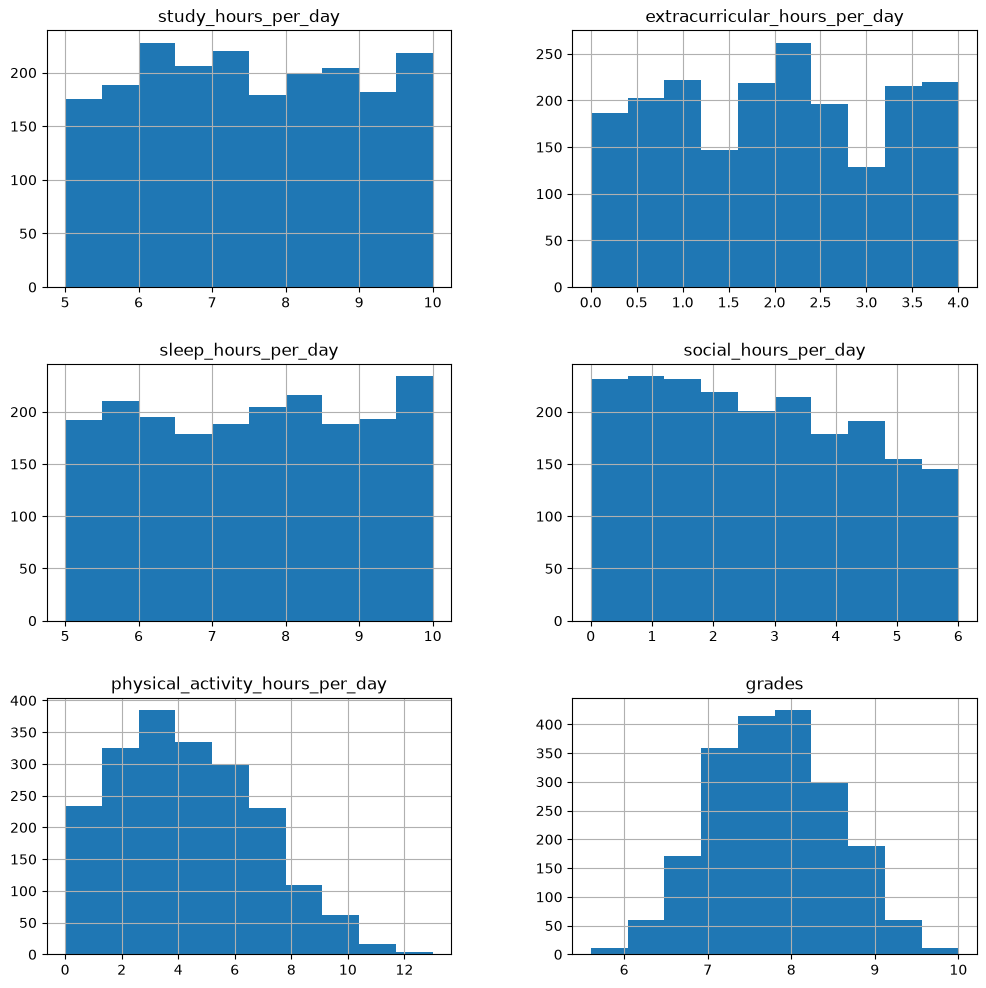

In [5]:
df.hist(figsize=(12, 12))

<Axes: >

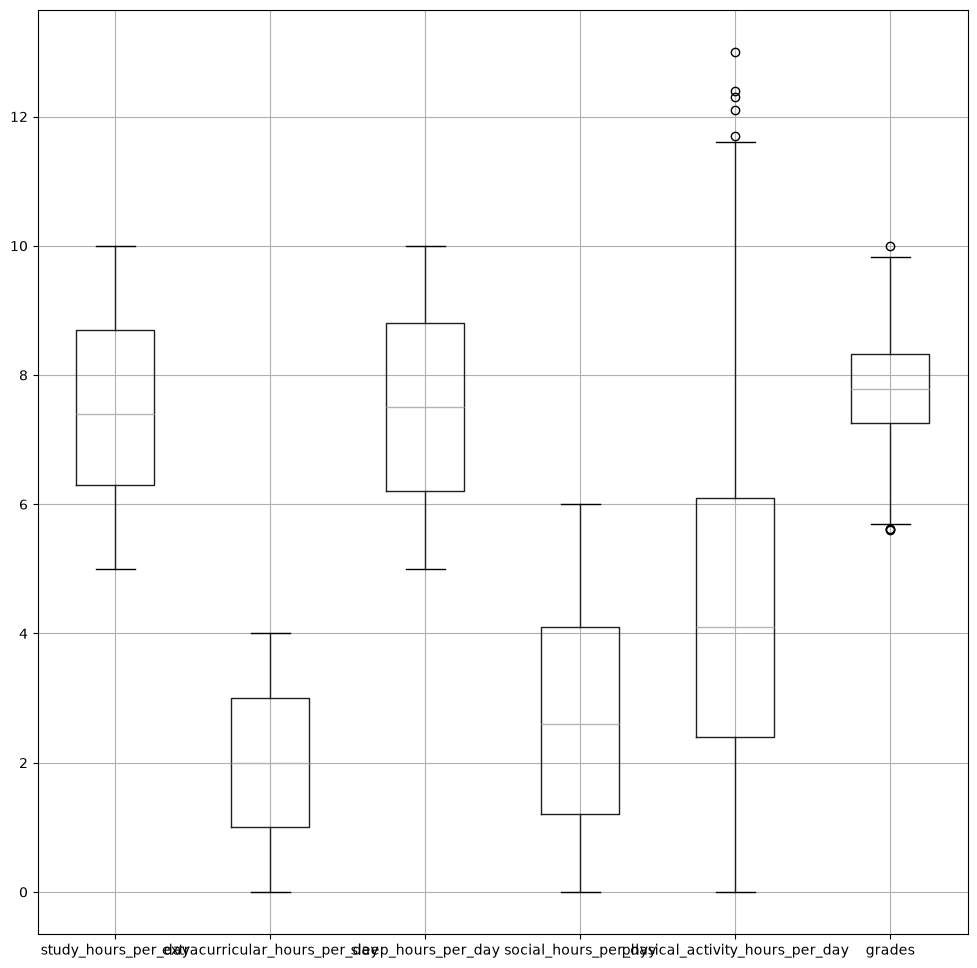

In [6]:
df.boxplot(figsize=(12, 12))

In [7]:
# Examining outliers: Physical Activity
pa: pd.DataFrame = df["physical_activity_hours_per_day"]
pa_q1: float = pa.quantile(0.25)
pa_q3: float = pa.quantile(0.75)
pa_iqr: float = pa_q3 - pa_q1
print(f"Physical Activity IQR: {pa_iqr}.")

pa_upper_outliers: pd.Series = pa > pa_q3 + pa_iqr * 1.5
print(f"Number of Physical Activity outliers: {pa_upper_outliers.value_counts()[True]}.")
print("Values:")
(df[pa_upper_outliers == True])

Physical Activity IQR: 3.6999999999999997.
Number of Physical Activity outliers: 5.
Values:


,study_hours_per_day,extracurricular_hours_per_day,sleep_hours_per_day,social_hours_per_day,physical_activity_hours_per_day,stress_level,gender,grades
62,5.1,0.5,5.2,0.2,13.0,High,Male,7.12
171,5.1,0.3,6.0,0.2,12.4,Low,Male,6.75
784,5.1,0.3,6.3,0.2,12.1,Low,Female,6.38
1174,5.3,0.3,5.9,0.2,12.3,High,Male,7.42
1715,5.4,0.2,6.3,0.4,11.7,Low,Female,6.32


## **Preprocessing**
### **Dealing with Outliers**
Outliers of physical activity will be dropped because they are not estimated to be representative.

In [8]:
# Examining outliers: Grades
g: pd.DataFrame = df["grades"]
g_q1: float = g.quantile(0.25)
g_q3: float = g.quantile(0.75)
g_iqr: float = g_q3 - g_q1
print(f"Grades IQR: {g_iqr}.")

g_upper_outliers: pd.Series = df["grades"] > g_q3 + g_iqr * 1.5
g_lower_outliers: pd.Series = df["grades"] < g_q1 - g_iqr * 1.5
g_outliers: pd.Series = g_upper_outliers | g_lower_outliers
print(f"Number of upper Grade outliers: {g_upper_outliers.value_counts()[True]}")
print(f"Number of lower Grade outliers: {g_lower_outliers.value_counts()[True]}")
print("Values:")
df[g_outliers]

Grades IQR: 1.0700000000000003.
Number of upper Grade outliers: 1
Number of lower Grade outliers: 3
Values:


,study_hours_per_day,extracurricular_hours_per_day,sleep_hours_per_day,social_hours_per_day,physical_activity_hours_per_day,stress_level,gender,grades
51,9.0,2.6,8.5,3.1,0.8,High,Female,10.00
331,5.1,1.0,8.8,0.8,8.3,Low,Male,5.62
764,5.5,1.8,6.7,5.2,4.8,Low,Male,5.60
1574,5.3,2.4,7.6,4.5,4.2,Low,Female,5.62


Outliers of grades don't seem suspicious so they won't be dropped.

`gender` and `stress level` need encoding as they are categorial variables.

In [19]:
# Categorial values of gender and stress level:
print("Different values for gender:")
print(df.value_counts("gender"))
print("\nDifferent values for stress level:")
print(df.value_counts("stress_level"))

Different values for gender:
gender
Male      1016
Female     984
Name: count, dtype: int64

Different values for stress level:
stress_level
High        1029
Moderate     674
Low          297
Name: count, dtype: int64


### **Transforming Categorical Data**

In [35]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer

transformer = ColumnTransformer(
    [
        ("transformed gender", OneHotEncoder(categories="auto", dtype=int, sparse_output=False), ["gender"]),
        ("transformed stress level", OrdinalEncoder(categories=[["Low", "Moderate", "High"]], dtype=int), ["stress_level"])
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)
transformer.set_output(transform="pandas")
df_numeric = transformer.fit_transform(df)

print("Transformed data set:")
df_numeric


Transformed data set:


,gender_Female,gender_Male,stress_level,study_hours_per_day,extracurricular_hours_per_day,sleep_hours_per_day,social_hours_per_day,physical_activity_hours_per_day,grades
0,0,1,1,6.9,3.8,8.7,2.8,1.8,7.48
1,1,0,0,5.3,3.5,8.0,4.2,3.0,6.88
2,0,1,0,5.1,3.9,9.2,1.2,4.6,6.68
3,0,1,1,6.5,2.1,7.2,1.7,6.5,7.20
4,0,1,2,8.1,0.6,6.5,2.2,6.6,8.78
...,...,...,...,...,...,...,...,...,...
1995,0,1,1,6.5,0.2,7.4,2.1,7.8,8.30
1996,1,0,1,6.3,2.8,8.8,1.5,4.6,6.62
1997,0,1,1,6.2,0.0,6.2,0.8,10.8,7.85
1998,0,1,2,8.1,0.7,7.6,3.5,4.1,7.60


Now all values can be used as numerical for models requiring numeric-only input.

## **Investigating Data**
### **Investigating Correlation**

In [42]:
# Compute correlation matrix:
correlation_matrix = df_numeric.corr()

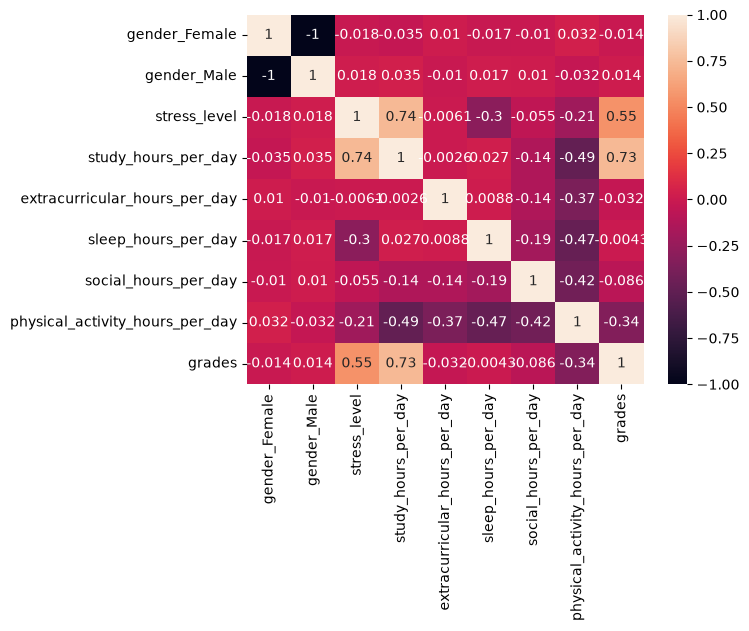

In [44]:
# Plot correlation matrix as heatmap:
ax = sbn.heatmap(df_numeric.corr(), annot=True)